# 04 Global vs specialized models

**Decision:** train one LightGBM model on every product, or a separate model for each group of products?

A global model pools data across products: it learns from all 2,000 series. A specialized model sees only its own group, so it can learn that group's patterns, but it has less data to learn from.

1. Understanding the groups
2. Training specialized models
3. Comparing strategies

The training loop fits about 250 LightGBM models and takes about four minutes; run it before the session.

In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, H, FREQ, ALL_CUTOFFS, DEV_CUTOFFS, TEST_CUTOFF
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS
from shared.evaluation import score
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard

panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]

## 1. Understanding the groups

Every product belongs to a department, a class within it and a subclass within that. These are fixed item attributes, so they are known at every cutoff. A missing value forms an `Unknown` group.

In [3]:
items = panel.drop_duplicates("unique_id").set_index("unique_id")
hierarchy = {level: items[f"{level}_id"].astype("string").fillna("Unknown") for level in ["department", "class", "subclass"]}

MIN_SERIES = 10      # a group gets its own model only with at least this many products

group_sizes = {level: membership.value_counts() for level, membership in hierarchy.items()}
pd.DataFrame({
    "groups": {level: len(sizes) for level, sizes in group_sizes.items()},
    "median_products": {level: sizes.median() for level, sizes in group_sizes.items()},
    "largest_group": {level: sizes.max() for level, sizes in group_sizes.items()},
    f"groups_with_{MIN_SERIES}+": {level: (sizes >= MIN_SERIES).sum() for level, sizes in group_sizes.items()},
    f"products_in_groups_with_{MIN_SERIES}+": {level: sizes[sizes >= MIN_SERIES].sum() / len(items) for level, sizes in group_sizes.items()},
}).round(2)

,groups,median_products,largest_group,groups_with_10+,products_in_groups_with_10+
department,126,10.0,100,65,0.87
class,345,4.0,56,63,0.50
subclass,773,2.0,27,23,0.15


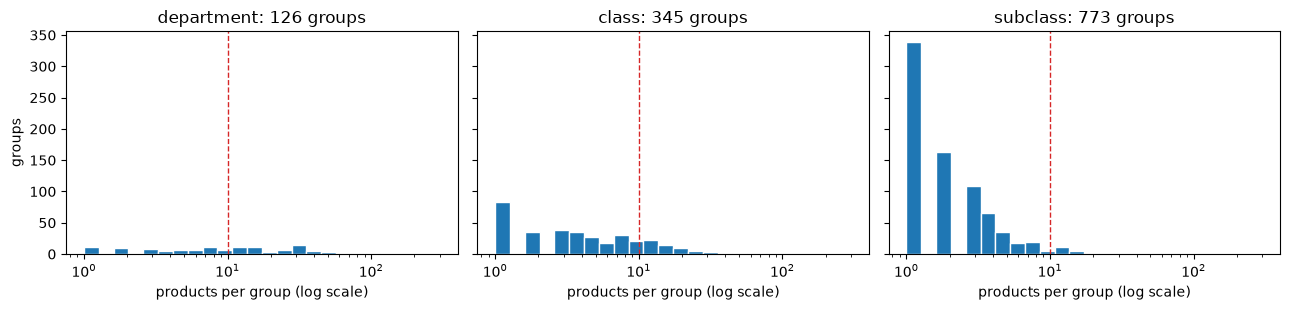

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
bins = np.geomspace(1, 300, 25)
for ax, (level, sizes) in zip(axes, group_sizes.items()):
    ax.hist(sizes, bins=bins, edgecolor="white")
    ax.axvline(MIN_SERIES, color="tab:red", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set(title=f"{level}: {len(sizes)} groups", xlabel="products per group (log scale)")
axes[0].set_ylabel("groups")
plt.tight_layout()

The finer the level, the smaller the groups. A product has about 90 weeks of training history at the final cutoff, so a subclass with three products trains a model on under 300 rows, while the global model trains on about 185,000. With LightGBM's `min_child_samples=50`, a tree fitted to a few hundred rows can make only a handful of splits.

The red line is `MIN_SERIES`. Groups below it get no model of their own. Only 23 of 773 subclasses reach ten products.

### Volume tiers

The hierarchy groups products by what they are. Products can also be grouped by how they sell. A simple version is three volume tiers: thirds by mean weekly sales. Unlike the hierarchy, tiers are recomputed at each cutoff from the training history only, so a product can change tier between cutoffs.

In [5]:
def volume_tiers(history):
    mean_sales = history.groupby("unique_id").y.mean()
    return pd.qcut(mean_sales.rank(method="first"), 3, labels=["low", "mid", "high"]).astype(str)


volume_tiers(actuals[actuals.ds <= TEST_CUTOFF]).value_counts()

y
high    667
low     667
mid     666
Name: count, dtype: int64

## 2. Training specialized models

One function serves every grouping. It trains one MLForecast model per group with at least `MIN_SERIES` products and stacks their forecasts. Products in smaller groups get the **global fallback**: the global model's forecast.

Each specialized model has the configuration of the global model from notebook 02: same lags, rolling means, calendar terms, per-series standardization and LightGBM parameters. Only the training data changes. The global model is `lgbm_baseline` from notebook 02, loaded rather than refit.

In [6]:
def fit_per_group(history, membership, name, global_forecast):
    """One MLForecast model per group with at least MIN_SERIES series; the global forecast for the rest."""
    membership = membership[membership.index.isin(history.unique_id.unique())]
    sizes = membership.value_counts()
    trained = membership[membership.isin(sizes[sizes >= MIN_SERIES].index)]

    forecasts = []
    for group, ids in trained.groupby(trained).groups.items():
        mlf = MLForecast(
            models={name: lgb.LGBMRegressor(**LGB_PARAMS)},
            freq=FREQ,
            lags=LAGS,
            lag_transforms=LAG_TRANSFORMS,
            date_features=DATE_FEATURES,
            target_transforms=[LocalStandardScaler()],
            num_threads=1,
        )
        mlf.fit(history[history.unique_id.isin(ids)])
        forecasts.append(mlf.predict(H))

    fallback = global_forecast[~global_forecast.unique_id.isin(trained.index)].rename(columns={"lgbm_baseline": name})
    return pd.concat(forecasts + [fallback])

The same function runs at every cutoff for the three hierarchy levels and the volume tiers. Each tier holds about 667 products, so the tiers never fall back.

In [7]:
baseline = load_forecasts(["02_ml_baseline"]).query("model == 'lgbm_baseline'")

forecasts = []
for cutoff in ALL_CUTOFFS:
    history = actuals[actuals.ds <= cutoff]
    global_forecast = baseline[baseline.cutoff == cutoff][["unique_id", "ds", "yhat"]].rename(columns={"yhat": "lgbm_baseline"})

    groupings = {
        "lgbm_department_part": hierarchy["department"],
        "lgbm_class_part": hierarchy["class"],
        "lgbm_subclass_part": hierarchy["subclass"],
        "lgbm_velocity_std": volume_tiers(history),
    }
    for name, membership in groupings.items():
        preds = fit_per_group(history, membership, name, global_forecast)
        experiment = "04_global_vs_specialized" if name == "lgbm_velocity_std" else "04_partition_granularity"
        forecasts.append(to_long(preds, cutoff, experiment))

forecasts = pd.concat(forecasts)

## 3. Comparing strategies

The table compares the statistical baselines from notebook 01, the global model from notebook 02, the specialized models above, and `lgbm_categorical` from notebook 03.

`lgbm_categorical` is one global model that also gets department, class and subclass as categorical features: **specialization through features** rather than through separate models. Its feature configuration differs from the other LightGBM rows, so it is a reference, not part of a controlled partitioning comparison.

- `models` and `specialized_share`: models trained and the share of products with a specialized model, at the final cutoff.
- `dev_wins_vs_global`: the number of the seven development cutoffs at which the model beats the global model (`lgbm_baseline`) on WAPE.
- Development WAPE, bias, mean RMSSE and APC come from the seven development cutoffs. Final WAPE is the final 14 weeks (exploratory, see `shared/README.md`).

In [8]:
reference = load_forecasts(["01_baselines", "02_ml_baseline", "03_exogenous"])
reference = reference[reference.model.isin(["SeasonalNaive", "HistoricAverage", "lgbm_baseline", "lgbm_categorical"])]
candidates = pd.concat([reference, forecasts])

dev = leaderboard(candidates, actuals, scope="dev").set_index("model")
final = leaderboard(candidates, actuals, scope="test").set_index("model")

by_cutoff = pd.concat([score(candidates[candidates.cutoff == c], actuals, rmsse=False).assign(cutoff=c) for c in DEV_CUTOFFS])
wape_by_cutoff = by_cutoff.pivot(index="model", columns="cutoff", values="wape")
wins = (wape_by_cutoff < wape_by_cutoff.loc["lgbm_baseline"]).sum(axis=1)

final_series = actuals[actuals.ds <= TEST_CUTOFF].unique_id.unique()
final_groups = {f"lgbm_{level}_part": membership for level, membership in hierarchy.items()}
final_groups["lgbm_velocity_std"] = volume_tiers(actuals[actuals.ds <= TEST_CUTOFF])
sizes = {name: membership[membership.index.isin(final_series)].value_counts() for name, membership in final_groups.items()}

strategy = {
    "SeasonalNaive": "local statistical, one per product",
    "HistoricAverage": "local statistical, one per product",
    "lgbm_baseline": "global",
    "lgbm_department_part": "per department",
    "lgbm_class_part": "per class",
    "lgbm_subclass_part": "per subclass",
    "lgbm_velocity_std": "per volume tier",
    "lgbm_categorical": "global, hierarchy as categorical features",
}
models = {"SeasonalNaive": 2000, "HistoricAverage": 2000, "lgbm_baseline": 1, "lgbm_categorical": 1}
models |= {name: (s >= MIN_SERIES).sum() for name, s in sizes.items()}
specialized = {name: s[s >= MIN_SERIES].sum() / len(final_series) for name, s in sizes.items()}

comparison = pd.DataFrame({
    "strategy": strategy,
    "models": models,
    "specialized_share": specialized,
    "dev_wape": dev.wape,
    "dev_wins_vs_global": wins,
    "final_wape": final.wape,
    "dev_bias": dev.bias,
    "dev_mean_rmsse": dev.mean_rmsse,
    "dev_apc": dev.apc,
}).loc[list(strategy)]
comparison.loc[["SeasonalNaive", "HistoricAverage", "lgbm_baseline"], "dev_wins_vs_global"] = np.nan
comparison.round(3)

,strategy,models,specialized_share,dev_wape,dev_wins_vs_global,final_wape,dev_bias,dev_mean_rmsse,dev_apc
SeasonalNaive,"local statistical, one per product",2000,NaN,0.408,NaN,0.438,-0.042,1.850,0.000
HistoricAverage,"local statistical, one per product",2000,NaN,0.426,NaN,0.426,-0.060,1.791,0.018
lgbm_baseline,global,1,NaN,0.449,NaN,0.419,0.139,1.865,0.129
lgbm_department_part,per department,65,0.873,0.439,5.0,0.406,0.106,1.867,0.189
lgbm_class_part,per class,63,0.501,0.433,7.0,0.424,0.088,1.844,0.164
lgbm_subclass_part,per subclass,23,0.154,0.440,7.0,0.413,0.129,1.858,0.139
lgbm_velocity_std,per volume tier,3,1.000,0.443,5.0,0.432,0.134,1.861,0.137
lgbm_categorical,"global, hierarchy as categorical features",1,NaN,0.423,7.0,0.400,0.103,1.851,0.149


### Reading the result

- **Partitioning helps the basic global model a little.** Department, class and subclass models lower development WAPE from 0.449 to between 0.433 and 0.440, and beat the global model at five to seven of the seven development cutoffs. Volume tiers reach 0.443. Most of the gain is less overforecasting: bias falls from +0.139 to between +0.088 and +0.134.
- **It does not beat the statistical baselines.** Seasonal naive (0.408) and historic average (0.426) stay ahead on development WAPE.
- **The final window ranks differently.** Department (0.406) and subclass (0.413) beat the global model (0.419); class (0.424) and volume tiers (0.432) do not.
- **Specialization has costs.** Department partitioning trains 65 models instead of one, and every partition revises its forecasts more (development APC 0.137 to 0.189, against 0.129). At the finer levels most products fall back to the global model: half by class and 85% by subclass.
- **Specialization through features works better here.** `lgbm_categorical` is one model with the hierarchy as categorical features. It scores 0.423 on development (better at all seven cutoffs) and 0.400 on the final window, ahead of every partition. Its feature configuration differs, so this shows that the hierarchy carries useful information, not that features beat partitions in a controlled test.

Specialized models make most sense when groups behave differently in ways the features cannot express, when each group is large enough to train on, or when groups must be retrained or governed separately. Grouping by demand behavior (volume, intermittency, seasonality) instead of the hierarchy is the natural next step; the volume tiers are its simplest form.

Save the specialized forecasts. `04_global_vs_specialized` also holds three earlier research models that notebook 07 uses as candidates (`lgbm_global_minmax`, `lgbm_dept_raw`, `lgbm_dept_std`; see `experiments/04_research/`). Only the volume-tier rows are replaced, and the other models are kept as they are.

In [9]:
save_forecasts(forecasts[forecasts.experiment == "04_partition_granularity"], "04_partition_granularity")

saved = load_forecasts(["04_global_vs_specialized"])
volume = forecasts[forecasts.experiment == "04_global_vs_specialized"]
save_forecasts(pd.concat([saved[saved.model != "lgbm_velocity_std"], volume]), "04_global_vs_specialized")